In [114]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [115]:
# y = 0.8x^2 + 0.9x + 2
X=6*np.random.rand(200,1)-3
y=0.8*X**2+0.9*X+2+np.random.randn(200,1)

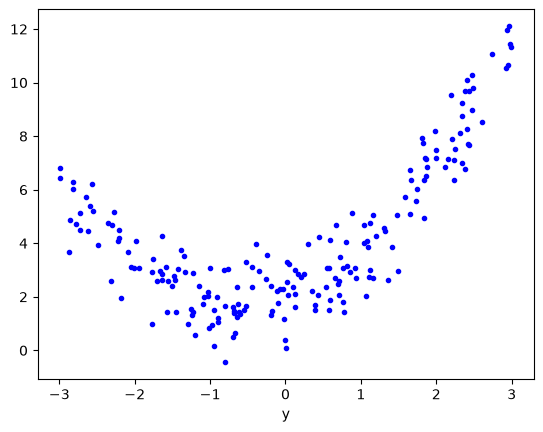

In [116]:
# visulize the data
plt.plot(X,y,".b")
plt.xlabel('X')
plt.xlabel('y')
plt.show()

# Apply on linear regression

In [117]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

lr=LinearRegression()

lr.fit(X_train,y_train)

y_pred=lr.predict(X_test)

In [118]:
print("R2_score",r2_score(y_test,y_pred))

R2_score 0.39470057751202914


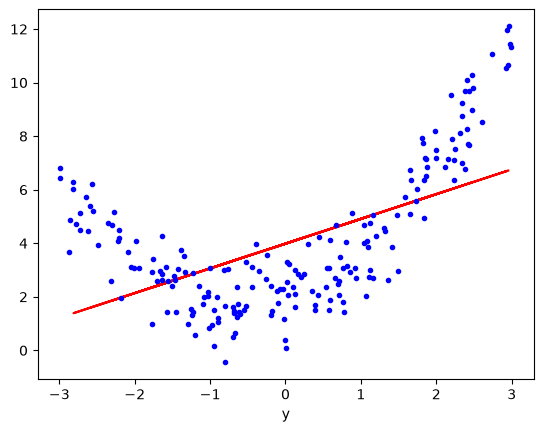

In [119]:
# visulize the data
plt.plot(X_test,y_pred,color='red')
plt.plot(X,y,".b")
plt.xlabel('X')
plt.xlabel('y')
plt.show()

# now Apply on polynomial regression with degree=2

In [120]:
poly=PolynomialFeatures(degree=2,include_bias=True)

X_train_transformed=poly.fit_transform(X_train)
X_test_transformed=poly.transform(X_test)

lr1=LinearRegression()
lr1.fit(X_train_transformed,y_train)
y_pred1=lr1.predict(X_test_transformed)


In [121]:
print("R2_score for poly: ",r2_score(y_test,y_pred1))

R2_score for poly:  0.8754004415150204


In [122]:
print(X_test[0])
print(X_test_transformed[0]) # beceause i included the bias

[2.95541363]
[1.         2.95541363 8.73446971]


In [123]:
print(lr1.coef_)
print(lr1.intercept_)

[[0.         0.91545667 0.77744266]]
[1.92735684]


In [124]:
X_new=np.linspace(-3,3,200).reshape(200,1)
X_new_poly=poly.transform(X_new)
y_new=lr1.predict(X_new_poly)

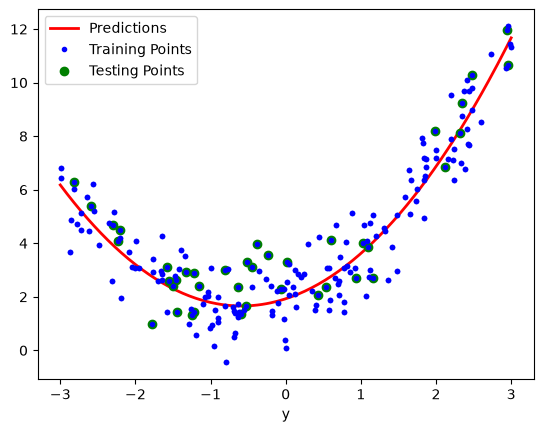

In [125]:
# visulize the data
plt.plot(X_new,y_new,'r-',linewidth=2,label='Predictions')
plt.plot(X_train,y_train,'b.',label='Training Points')
plt.plot(X_test,y_test,'go',label='Testing Points')
plt.plot(X,y,".b")
plt.xlabel('X')
plt.xlabel('y')
plt.legend()
plt.show()

# visulize with higher degree polynomial

In [126]:
def polynomial_regression(degree):

    polynomial_model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lin_reg", LinearRegression())
    ])

    polynomial_model.fit(X_train, y_train)

    X_new = np.linspace(-3, 3, 100).reshape(-1, 1)
    y_new = polynomial_model.predict(X_new)

    plt.figure(figsize=(8,5))

    plt.plot(X_new, y_new, 'r-', linewidth=2, label=f'Degree {degree}')
    plt.scatter(X_train, y_train, color='blue', label='Training')
    plt.scatter(X_test, y_test, color='green', label='Testing')

    plt.xlabel("X")
    plt.ylabel("y")
    plt.legend()
    plt.axis([-3, 3, 0, 10])
    plt.show()

    



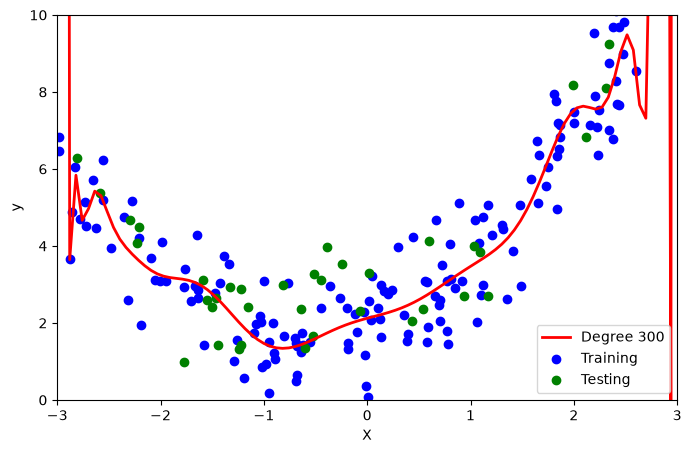

In [136]:
polynomial_regression(300)


In [137]:
poly.powers_

array([[0],
       [1],
       [2]])

## Applying Gradient Descent

c:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\.venv\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


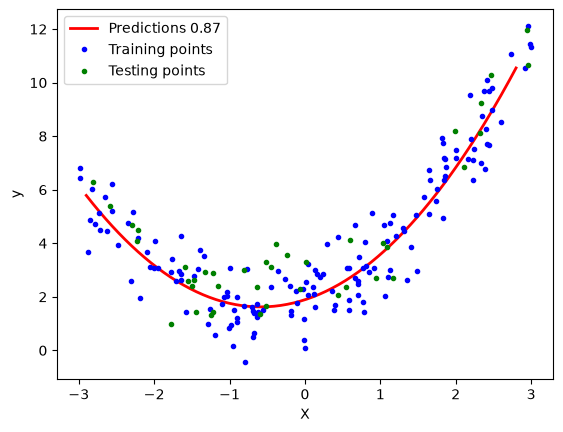

In [138]:
poly = PolynomialFeatures(degree=2)

X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.transform(X_test)

sgd = SGDRegressor(max_iter=100)
sgd.fit(X_train_trans,y_train)

X_new=np.linspace(-2.9, 2.8, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
y_new = sgd.predict(X_new_poly)

y_pred = sgd.predict(X_test_trans)

plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions " + str(round(r2_score(y_test,y_pred),2)))
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

# 3D polynomial regression

In [139]:
# z = x^2 + y^2 + 0.2x + 0.2y + 0.1xy + 2
x = 7 * np.random.rand(100, 1) - 2.8
y = 7 * np.random.rand(100, 1) - 2.8

z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y +2 + np.random.randn(100, 1)


In [143]:
import plotly.express as px


df = px.data.iris()
fig = px.scatter_3d(df, x=x.ravel(), y=y.ravel(), z=z.ravel())
fig.show()

In [144]:

lr = LinearRegression()
lr.fit(np.array([x,y]).reshape(100,2),z)

x_input = np.linspace(x.min(), x.max(), 10)
y_input = np.linspace(y.min(), y.max(), 10)
xGrid, yGrid = np.meshgrid(x_input,y_input)

final = np.vstack((xGrid.ravel().reshape(1,100),yGrid.ravel().reshape(1,100))).T

z_final = lr.predict(final).reshape(10,10)

In [145]:

import plotly.graph_objects as go

fig = px.scatter_3d(df, x=x.ravel(), y=y.ravel(), z=z.ravel())

fig.add_trace(go.Surface(x = x_input, y = y_input, z =z_final ))

fig.show()

In [147]:

X_multi = np.array([x,y]).reshape(100,2)
X_multi.shape

(100, 2)

In [156]:

poly = PolynomialFeatures(degree=10)
X_multi_trans = poly.fit_transform(X_multi)

print("Input",poly.n_input_features_)
print("Ouput",poly.n_output_features_)
print("Powers\n",poly.powers_)

AttributeError: 'PolynomialFeatures' object has no attribute 'n_input_features_'

In [157]:

X_multi_trans.shape

(100, 66)

In [158]:

lr = LinearRegression()
lr.fit(X_multi_trans,z)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 66)","[[-0. ,-0.2 ,-0.29,...,-0.01,-0. ,-0. ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[10.09]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,66
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(49)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](66,)","[4541550.32,3976153.26,2832406.88,..., 0.27, 0.21, 0. ]"


In [159]:

X_test_multi = poly.transform(final)

In [160]:
z_final = lr.predict(X_multi_trans).reshape(10,10)

In [161]:
fig = px.scatter_3d(x=x.ravel(), y=y.ravel(), z=z.ravel())

fig.add_trace(go.Surface(x = x_input, y = y_input, z =z_final))

fig.update_layout(scene = dict(zaxis = dict(range=[0,35])))

fig.show()